# How large does the outbreak get? The final size and why it ignores time

**Question:** What share of a population does an outbreak infect in the end, why does that share depend on $R_0$ and not on how fast the outbreak runs, and when does the engine's own run fail to reach it?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can solve the final-size relation by iteration and watch it converge, place the attack rates the engine simulates on the curve of the relation, show that two outbreaks with the same $R_0$ and different speeds end at the same size, and tell how the first infected people and the length of the horizon change the answer.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and the pipeline's modules, prints the versions and defines the reader of the cases' parameters.

In [1]:
# the tools, their versions, the pipeline's modules and the reader of the cases' parameters
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.sir import simulate
from pipeline.oracles import final_size

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Data

The parameters of the five cases of the example.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json`, for the parameters only; every course shown here is computed by the engine.

## Method

Divide the equation for $S$ by the equation for $R$ in the SIR system: the time cancels and $dS/dR = -(\beta / \gamma) S / N$, which integrates to $S = S_0 \, e^{-R_0 R / N}$. When the outbreak has ended nobody is infected, so $S_\infty = N - R_\infty$ and the share ever infected $z = R_\infty / N$ satisfies

$$1 - z = (1 - i_0)\, e^{-R_0 z}$$

with $i_0 = I_0 / N$ (Kermack and McKendrick, 1927; Miller, 2012). The contact rate and the recovery rate appear only through their ratio and time does not appear at all. For $i_0 \to 0$ and $R_0 \le 1$ the only solution is $z = 0$. The function `final_size` of `data-pipeline/pipeline/oracles.py` solves it by fixed-point iteration: it starts at $z = 1$ and repeats $z \leftarrow 1 - (1 - i_0) e^{-R_0 z}$ until two consecutive values differ by less than $10^{-12}$. It shares no code with the engine, so a disagreement between the two says something about one of them.

First the iteration itself, for the epidemic case, $R_0 = 2.75$. The cell keeps every iterate and prints the first six, the number of iterations and the solution. The iteration starts at the worst guess, everybody infected, so the first iterates come down toward the answer.

In [2]:
# solve the final-size relation for the epidemic case by fixed-point iteration and keep every iterate
r0 = 2.75
iterates = []
z = final_size(r0, trace=iterates)
print("first iterates", [round(float(v), 5) for v in iterates[:6]])
print(f"iterations: {len(iterates)}, z = {z:.6f}")

first iterates [0.93607, 0.92379, 0.92117, 0.9206, 0.92047, 0.92044]
iterations: 18, z = 0.920437


The iterates 0.93607, 0.92379, 0.92117 settle on 0.92044 within six steps, and the loop stops after 18 when the change is below the tolerance. A solution that comes this fast is not guaranteed at every $R_0$: the next cell repeats the iteration for four values, from a barely super-critical 1.2 to a violent 6.0, and counts the iterations each one needs.

In [3]:
# the same iteration for four values of R0, to see how many steps each one needs
traces = {}
for value in (1.2, 1.5, 2.75, 6.0):
    traces[value] = []
    final_size(value, trace=traces[value])
    print(f"R0 = {value:4.2f}  z = {traces[value][-1]:.4f}  {len(traces[value]):4d} iterations")

R0 = 1.20  z = 0.3137   127 iterations
R0 = 1.50  z = 0.5828    55 iterations
R0 = 2.75  z = 0.9204    18 iterations
R0 = 6.00  z = 0.9975     7 iterations


The next cell draws the iterates against the iteration number for the four values of $R_0$.

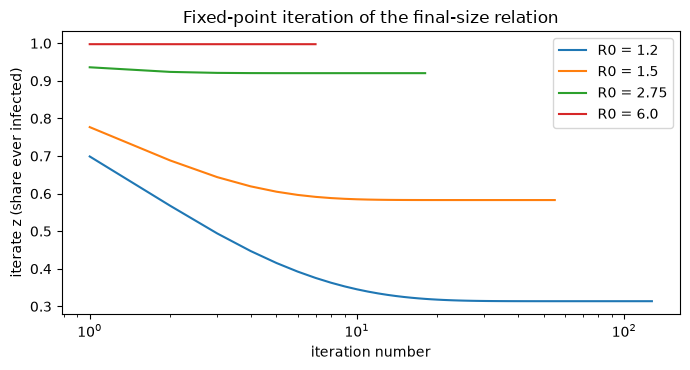

In [4]:
# draw the iterates against the iteration number for the four values of R0
fig, ax = plt.subplots(figsize=(7, 3.8))
for value, trace in traces.items():
    ax.plot(range(1, len(trace) + 1), trace, label=f"R0 = {value}")
ax.set_xscale("log")
ax.set_xlabel("iteration number")
ax.set_ylabel("iterate z (share ever infected)")
ax.set_title("Fixed-point iteration of the final-size relation")
ax.legend()
fig.tight_layout()
plt.show()

Each curve is an iteration, and they all fall from 1 toward their own answer. For $R_0 = 6$ it is over in 7 steps; for $R_0 = 1.2$ it takes 127, because close to the threshold the map $z \mapsto 1 - e^{-R_0 z}$ is almost tangent to the diagonal and the iterates creep. The figure uses a logarithmic axis for the iteration number so that both extremes are visible. It says nothing about the engine yet; the next cell brings it in by computing the relation over a grid of $R_0$ and simulating every case that has infected people.

In [5]:
# the final-size curve over R0, and the attack rate the engine simulates for every case that has infected people
grid = np.linspace(0.5, 6.5, 121)
curve = [final_size(g) for g in grid]
points = {}
for case_id in CASES:
    p = params_of(case_id)
    if p.I0 == 0:
        continue
    r0_case = p.beta / p.gamma
    points[case_id] = (r0_case, simulate(p).attack_rate)
    print(f"{case_id:18s} R0 = {r0_case:4.2f}  z = {final_size(r0_case, p.I0 / p.N):.4f}", end="  ")
    print(f"simulated {points[case_id][1]:.4f}")

EX01_subcritical   R0 = 0.72  z = 0.0018  simulated 0.0018
EX02_epidemic      R0 = 2.75  z = 0.9205  simulated 0.9237
EX03_fast_burn     R0 = 6.00  z = 0.9975  simulated 0.9982
EX04_slow_spread   R0 = 1.20  z = 0.3156  simulated 0.2993


The next cell draws the curve of the relation and places each case on it at its $R_0$ and its simulated attack rate.

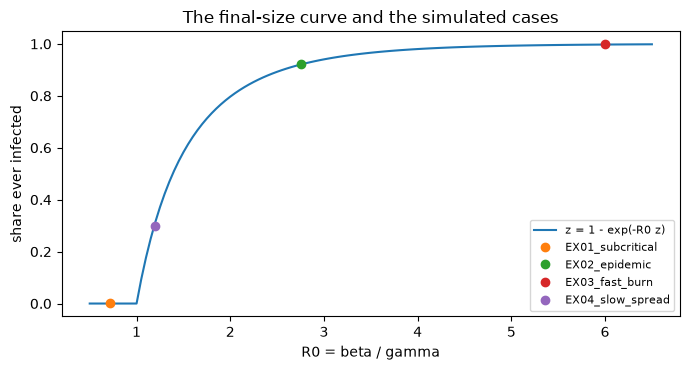

In [6]:
# draw the relation's curve and place each case at its R0 and its simulated attack rate
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, curve, label="z = 1 - exp(-R0 z)")
for case_id, (r0_case, attack) in points.items():
    ax.plot([r0_case], [attack], "o", label=case_id)
ax.set_xlabel("R0 = beta / gamma")
ax.set_ylabel("share ever infected")
ax.set_title("The final-size curve and the simulated cases")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The curve is zero up to $R_0 = 1$, climbs steeply to 0.5828 at $R_0 = 1.5$ and flattens against 1 for large $R_0$: no outbreak infects everybody, and the last few percent are hard to reach. The engine's cases sit on it. The epidemic and the fast burn are 0.0032 and 0.0007 above the relation, which is the Euler arithmetic measured in notebook 02 of topic 01; the sub-critical case sits at 0.0018, the initial infections and almost nobody else. The slow spread is the odd one out, 0.2993 against 0.3156. The figure cannot say why, and the horizon cell below does.

Now the claim that time does not matter. The cell runs the epidemic case and a twin whose contact rate and recovery rate are both doubled, so the outbreak runs twice as fast and $R_0$ is still 2.75. If the relation is right, the peak should come about twice as early and the attack rates should be nearly the same.

In [7]:
# the epidemic case and a twin twice as fast, which has the same R0 = 2.75
base = params_of("EX02_epidemic")
twin = replace(base, beta=2 * base.beta, gamma=2 * base.gamma)
runs = {"EX02_epidemic": simulate(base), "twice as fast": simulate(twin)}
for label, r in runs.items():
    print(f"{label:16s} peak {r.peak_I:7.0f}  on day {r.t_peak:6.2f}  attack rate {r.attack_rate:.4f}")

EX02_epidemic    peak   27345  on day  24.25  attack rate 0.9237
twice as fast    peak   27836  on day  12.50  attack rate 0.9269


The next cell draws the infected people of the two runs on the same axes.

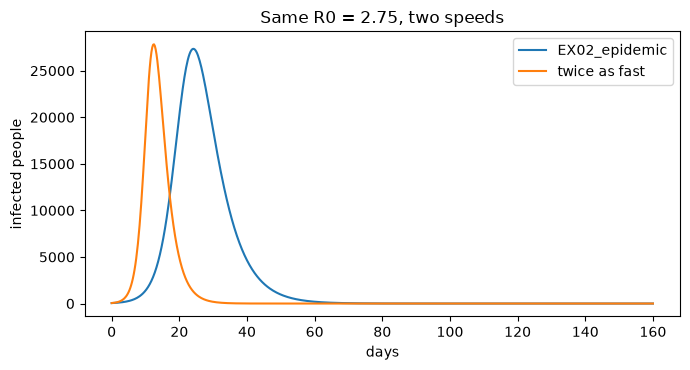

In [8]:
# draw the infected people of the two runs on the same axes
fig, ax = plt.subplots(figsize=(7, 3.8))
for label, r in runs.items():
    ax.plot(r.t, r.I, label=label)
ax.set_xlabel("days")
ax.set_ylabel("infected people")
ax.set_title("Same R0 = 2.75, two speeds")
ax.legend()
fig.tight_layout()
plt.show()

The twin peaks on day 12.50 instead of day 24.25, half the time, and its curve is the same hump compressed in time, but both outbreaks end with nearly the same share infected, 0.9237 and 0.9269. The final size is a property of $R_0$ and the course in time is a property of the rates. The difference of 0.0032 between the two attack rates is not physics: it is the Euler error again, larger for the faster twin because a quarter of a day covers more of its course. The figure shows the compression and the equal areas under the tails; it does not show the small gap.

The relation has a second argument, the initial infected share $i_0$, that the earlier cells left at zero. The next cell raises the first infected people to 5000 and 20000 and compares three numbers: the relation with $i_0$, the relation without it, and the engine.

In [9]:
# raise the first infected people to 5000 and to 20000: the relation follows the engine when it is given i0
for first in (50, 5000, 20000):
    q = replace(base, I0=first)
    z_i0 = final_size(2.75, first / base.N)
    print(f"I0 = {first:6d}  z(R0, i0) = {z_i0:.4f}  z(R0) = {final_size(2.75):.4f}", end="  ")
    print(f"simulated {simulate(q).attack_rate:.4f}")

I0 =     50  z(R0, i0) = 0.9205  z(R0) = 0.9204  simulated 0.9237
I0 =   5000  z(R0, i0) = 0.9254  z(R0) = 0.9204  simulated 0.9287
I0 =  20000  z(R0, i0) = 0.9396  z(R0) = 0.9204  simulated 0.9428


With 20000 people infected at the start, one fifth of the town, the relation without $i_0$ is wrong by 0.019, while the relation with $i_0$ stays within 0.0033 of the engine in all three rows. That constant gap is the Euler error again, and it says the relation, with its second argument, describes what the engine does. The last case is the slow spread, whose attack rate stopped short of the relation. The cell runs it at its own 160-day horizon and at 300 days.

In [10]:
# the slow-spread case at its 160-day horizon and at 300 days, against the relation
slow = params_of("EX04_slow_spread")
z_slow = final_size(slow.beta / slow.gamma, slow.I0 / slow.N)
for horizon in (160, 300):
    r = simulate(replace(slow, days=horizon))
    print(f"horizon = {horizon:3d}  attack rate {r.attack_rate:.4f}  z = {z_slow:.4f}")

horizon = 160  attack rate 0.2993  z = 0.3156
horizon = 300  attack rate 0.3162  z = 0.3156


## Results

**Answer:** An outbreak with $R_0 = 2.75$ and 50 first cases in 100000 people ends with 0.9205 of the population infected according to the relation, and the engine's 160-day run gives 0.9237, 0.0032 higher, the Euler error. The share depends on $R_0$ and not on speed: the twin outbreak that runs twice as fast peaks on day 12.50 instead of day 24.25 and still ends at 0.9269. The initial infected people matter only slightly, from 0.9205 at 50 to 0.9254 at 5000 and 0.9396 at 20000, and the relation tracks the engine within 0.0033 through all of them. The engine fails to reach the relation when the outbreak has not ended by the horizon: the slow spread, with $R_0 = 1.20$, has infected 0.2993 at day 160 against 0.3156 predicted, and reaches 0.3162 at day 300.

The relation describes the end of an outbreak in a closed, well-mixed population and says nothing about when it ends; it is a bound, not a forecast for any horizon. Near the threshold it is also slow to compute, 127 iterations at $R_0 = 1.2$, and the engine needs a long horizon to confirm it.

## Summary

- The final size $z$ solves $1 - z = (1 - i_0) e^{-R_0 z}$ and is found by a short fixed-point iteration, slow only close to the threshold.
- It depends on $R_0$ and the first infected share, not on the speed of the outbreak: a twin at twice the rates peaks twice as early and ends at the same size.
- The engine sits about 0.003 above the relation, its Euler error, wherever the outbreak has ended inside the horizon.
- The slow spread has not ended at day 160, and the relation describes its end only at day 300.
- Next: the same cases against a higher-order solver, in notebook 03 of topic 01.

## References

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine and the oracle of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/oracles.py`).